In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df_c = pd.read_csv('customers_clean.csv')

In [4]:
df_rt = pd.read_csv('returns_clean.csv')

In [13]:
df_pr = pd.read_csv('products_clean.csv')

In [5]:
df_rt.info()

<class 'pandas.DataFrame'>
RangeIndex: 2092 entries, 0 to 2091
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   return_id      2092 non-null   str    
 1   order_id       2092 non-null   str    
 2   product_id     2092 non-null   str    
 3   return_date    2092 non-null   str    
 4   return_reason  2092 non-null   str    
 5   refund_amount  2092 non-null   float64
 6   sales_amount   2092 non-null   float64
dtypes: float64(2), str(5)
memory usage: 200.0 KB


In [6]:
df_rt['return_date'] = pd.to_datetime(df_rt['return_date'])

In [7]:
df_c.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customer_id    5000 non-null   str  
 1   customer_name  5000 non-null   str  
 2   gender         5000 non-null   str  
 3   age            5000 non-null   int64
 4   state          5000 non-null   str  
 5   city           5000 non-null   str  
 6   signup_date    5000 non-null   str  
dtypes: int64(1), str(6)
memory usage: 517.9 KB


In [8]:
df_c['state'].unique()

<ArrowStringArray>
[  'West Bengal',         'Delhi',     'Karnataka',   'Maharashtra',
       'Gujarat', 'Uttar Pradesh',        'Kerala',     'Rajasthan',
    'Tamil Nadu',     'Telangana']
Length: 10, dtype: str

In [9]:
df_c['city'].unique()

<ArrowStringArray>
[   'Kolkata',  'New Delhi',     'Mysuru',     'Nagpur',      'Surat',
    'Lucknow',      'Noida',  'Bengaluru',       'Pune',      'Kochi',
     'Jaipur',    'Unknown', 'Coimbatore',    'Chennai',  'Hyderabad',
  'Ahmedabad',     'Mumbai']
Length: 17, dtype: str

In [10]:
df_c['signup_date'] = pd.to_datetime(df_c['signup_date'])

In [14]:
df_pr.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     600 non-null    str    
 1   product_name   600 non-null    str    
 2   category       600 non-null    str    
 3   sub_category   600 non-null    str    
 4   list_price     600 non-null    float64
 5   unit_cost      600 non-null    float64
 6   seller_id      600 non-null    str    
 7   quality_score  600 non-null    float64
dtypes: float64(3), str(5)
memory usage: 67.9 KB


In [15]:
df_pr['category'].unique()

<ArrowStringArray>
[         'Books',     'Electronic',         'Sports', 'Home & Kitchen',
        'Fashion',        'Grocery',         'Beauty',    'Electronics',
           'Toys']
Length: 9, dtype: str

In [16]:
df_pr['category'] = df_pr['category'].replace({'Electronic': 'Electronics'})

In [18]:
df_pr['category'].unique()

<ArrowStringArray>
[         'Books',    'Electronics',         'Sports', 'Home & Kitchen',
        'Fashion',        'Grocery',         'Beauty',           'Toys']
Length: 8, dtype: str

In [19]:
df_pr['sub_category'].unique()

<ArrowStringArray>
[         'Books - Type 2',    'Electronics - Type 3',
         'Sports - Type 2', 'Home & Kitchen - Type 2',
        'Fashion - Type 1',        'Fashion - Type 4',
        'Grocery - Type 1',        'Fashion - Type 2',
         'Beauty - Type 2',        'Grocery - Type 4',
         'Sports - Type 4', 'Home & Kitchen - Type 1',
          'Books - Type 1',    'Electronics - Type 1',
         'Beauty - Type 4',         'Sports - Type 1',
    'Electronics - Type 4',    'Electronics - Type 2',
 'Home & Kitchen - Type 4',           'Toys - Type 4',
         'Beauty - Type 3',          'Books - Type 4',
         'Sports - Type 3',        'Fashion - Type 3',
 'Home & Kitchen - Type 3',           'Toys - Type 3',
           'Toys - Type 1',         'Beauty - Type 1',
           'Toys - Type 2',          'Books - Type 3',
        'Grocery - Type 2',        'Grocery - Type 3']
Length: 32, dtype: str

In [20]:
df_pr.columns

Index(['product_id', 'product_name', 'category', 'sub_category', 'list_price',
       'unit_cost', 'seller_id', 'quality_score'],
      dtype='str')

In [21]:
df_rt.columns

Index(['return_id', 'order_id', 'product_id', 'return_date', 'return_reason',
       'refund_amount', 'sales_amount'],
      dtype='str')

### 1 . How many returns for each reason?

In [73]:
rf_r = df_rt.groupby(df_rt['return_reason'])['return_id'].count().sort_values(ascending = False).reset_index()

In [75]:
rf_r = rf_r.rename(columns={'return_id': 'returns'})

In [76]:
rf_r

,return_reason,returns
0,Defective,577
1,Not As Described,506
2,Size/Fit Issue,305
3,Wrong Item,294
4,Changed Mind,284
5,Unknown,126


### 2. How much money each reason costs?

In [37]:
lbr = df_rt.groupby('return_reason')['refund_amount'].sum().sort_values(ascending = False).reset_index()

In [38]:
lbr

,return_reason,refund_amount
0,Not As Described,2951438.46
1,Defective,2337868.94
2,Size/Fit Issue,1524592.60
3,Changed Mind,1209351.68
4,Wrong Item,1007693.80
5,Unknown,717878.30


In [83]:
lbr['refund_m'] = lbr['refund_amount']/1e6

In [84]:
lbr

,return_reason,refund_amount,refund_m
0,Not As Described,2951438.46,2.951438
1,Defective,2337868.94,2.337869
2,Size/Fit Issue,1524592.60,1.524593
3,Changed Mind,1209351.68,1.209352
4,Wrong Item,1007693.80,1.007694
5,Unknown,717878.30,0.717878


### 3. Reasons by category

In [41]:
r = df_rt.merge(df_pr[['product_id', 'category']], on= 'product_id', how = 'left')

In [42]:
r.head()

,return_id,order_id,product_id,return_date,return_reason,refund_amount,sales_amount,category
0,RET01729,O024764,P0172,2023-07-21,Size/Fit Issue,2441.66,2441.66,Sports
1,RET01379,O019631,P0206,2024-03-09,Wrong Item,770.10,770.10,Fashion
2,RET00985,O013896,P0419,2023-10-19,Defective,1469.72,1469.72,Toys
3,RET00242,O003589,P0339,2025-01-15,Defective,9756.60,9756.60,Fashion
4,RET00135,O002037,P0172,2023-05-16,Defective,1953.33,1953.33,Sports


In [66]:
r.groupby('category')['return_reason'].value_counts().unstack()

return_reason,Changed Mind,Defective,Not As Described,Size/Fit Issue,Unknown,Wrong Item
category,,,,,,
Beauty,16,34,30,18,7,23
Books,52,100,79,56,21,53
Electronics,38,75,83,40,20,32
Fashion,49,121,88,56,25,55
Grocery,15,15,20,8,3,14
Home & Kitchen,24,63,50,28,13,25
Sports,32,56,58,39,13,29
Toys,58,113,98,60,24,63


In [79]:
rbc = r.groupby('category')['return_reason'].value_counts(normalize = True).mul(100).unstack().reset_index()

In [80]:
rbc

return_reason,category,Changed Mind,Defective,Not As Described,Size/Fit Issue,Unknown,Wrong Item
0,Beauty,12.500000,26.562500,23.437500,14.062500,5.468750,17.968750
1,Books,14.404432,27.700831,21.883657,15.512465,5.817175,14.681440
2,Electronics,13.194444,26.041667,28.819444,13.888889,6.944444,11.111111
3,Fashion,12.436548,30.710660,22.335025,14.213198,6.345178,13.959391
4,Grocery,20.000000,20.000000,26.666667,10.666667,4.000000,18.666667
5,Home & Kitchen,11.822660,31.034483,24.630542,13.793103,6.403941,12.315271
6,Sports,14.096916,24.669604,25.550661,17.180617,5.726872,12.775330
7,Toys,13.942308,27.163462,23.557692,14.423077,5.769231,15.144231


## VISUALIZATION

In [81]:
rf_r['percent'] = rf_r['returns'] / rf_r['returns'].sum()*100

In [82]:
rf_r

,return_reason,returns,percent
0,Defective,577,27.581262
1,Not As Described,506,24.187380
2,Size/Fit Issue,305,14.579350
3,Wrong Item,294,14.053537
4,Changed Mind,284,13.575526
5,Unknown,126,6.022945


### 1. Why do customers return products?

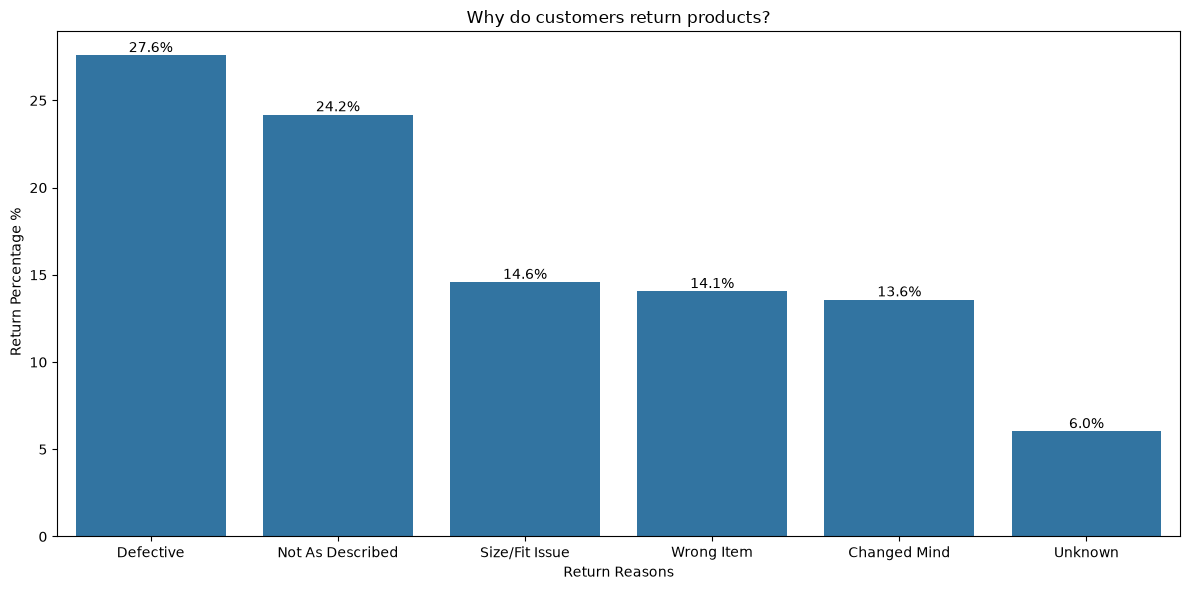

In [89]:
plt.figure(figsize=(12,6))
ax = sns.barplot(data = rf_r, x = 'return_reason', y = 'percent')
ax.bar_label(ax.containers[0], fmt = '%.1f%%')
plt.title('Why do customers return products?')
plt.xlabel('Return Reasons')
plt.ylabel(' Return Percentage %')
plt.tight_layout()
plt.show()

### 2. Money refunded by reason

In [90]:
lbr

,return_reason,refund_amount,refund_m
0,Not As Described,2951438.46,2.951438
1,Defective,2337868.94,2.337869
2,Size/Fit Issue,1524592.60,1.524593
3,Changed Mind,1209351.68,1.209352
4,Wrong Item,1007693.80,1.007694
5,Unknown,717878.30,0.717878


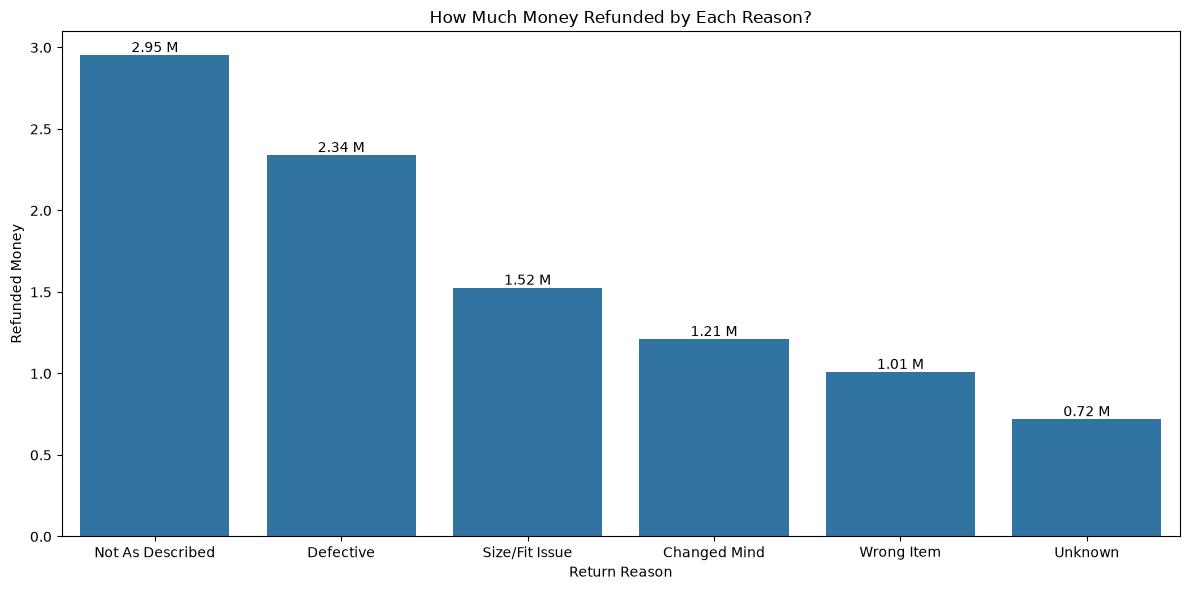

In [96]:
plt.figure(figsize=(12,6))
ap = sns.barplot(data = lbr, x = 'return_reason', y = 'refund_m')
ap.bar_label(ap.containers[0], fmt = '%.2f M')
plt.title('How Much Money Refunded by Each Reason?')
plt.xlabel('Return Reason')
plt.ylabel('Refunded Money')
plt.tight_layout()
plt.show()

In [ ]:
Not As Described costs the most (2.95M), even more than Defective (2.34M), so wrongly described products are the most expensive returns.

### 3 . Reasons inside each category

In [97]:
rbc

return_reason,category,Changed Mind,Defective,Not As Described,Size/Fit Issue,Unknown,Wrong Item
0,Beauty,12.500000,26.562500,23.437500,14.062500,5.468750,17.968750
1,Books,14.404432,27.700831,21.883657,15.512465,5.817175,14.681440
2,Electronics,13.194444,26.041667,28.819444,13.888889,6.944444,11.111111
3,Fashion,12.436548,30.710660,22.335025,14.213198,6.345178,13.959391
4,Grocery,20.000000,20.000000,26.666667,10.666667,4.000000,18.666667
5,Home & Kitchen,11.822660,31.034483,24.630542,13.793103,6.403941,12.315271
6,Sports,14.096916,24.669604,25.550661,17.180617,5.726872,12.775330
7,Toys,13.942308,27.163462,23.557692,14.423077,5.769231,15.144231


In [100]:
new_rbc = rbc.melt(id_vars = 'category', var_name = 'Reason', value_name = 'Percent')

In [101]:
new_rbc

,category,Reason,Percent
0,Beauty,Changed Mind,12.500000
1,Books,Changed Mind,14.404432
2,Electronics,Changed Mind,13.194444
3,Fashion,Changed Mind,12.436548
4,Grocery,Changed Mind,20.000000
5,Home & Kitchen,Changed Mind,11.822660
6,Sports,Changed Mind,14.096916
7,Toys,Changed Mind,13.942308
8,Beauty,Defective,26.562500
9,Books,Defective,27.700831


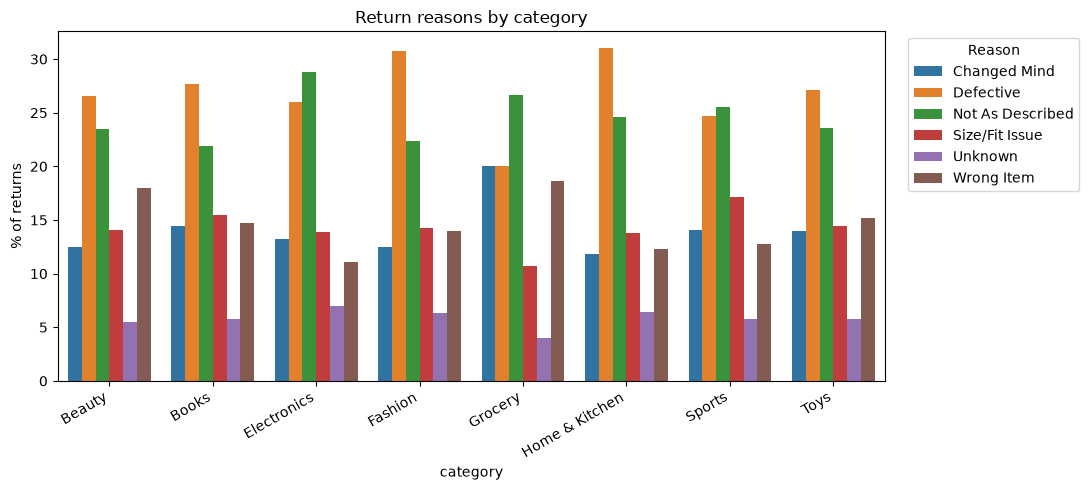

In [117]:
plt.figure(figsize=(11, 5))
sns.barplot(data=new_rbc, x='category', y='Percent', hue='Reason')
plt.ylabel('% of returns')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Reason', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.title('Return reasons by category')
plt.tight_layout(); plt.show()

## RECOMMENDATION 